# HSV Segmentation Demo

The HSV process we feed into the CNN, one step per cell:

1. Grab a picture from the dataset.
2. Convert it from RGB to HSV.
3. Apply thresholds (lower and upper limits on hue, saturation, **and** value) to build a **binary mask**: matching pixels turn white, everything else black.
4. Apply the mask to the original picture so only suspected lesion regions remain.
5. Draw boxes around those regions; these are the candidates the CNN will check.

OpenCV scales: **hue 0–179**, saturation 0–255, value 0–255.

In [1]:
# Colab only: uncomment and run once.
# !git clone https://github.com/<your-org>/apple-lesion-detection.git
# %cd apple-lesion-detection
# !pip install -q -r requirements.txt

In [2]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.hsv.segment import (apply_mask, candidate_boxes, clean_mask, draw_boxes,
                             leaf_region, segment_leaf, synthetic_leaf,
                             threshold_mask, to_hsv)
from src.hsv.thresholds import DISEASE_RANGES, HSVRange

def show(images, titles, cmaps=None, size=4):
    cmaps = cmaps or [None] * len(images)
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, img, title, cmap in zip(np.atleast_1d(axes), images, titles, cmaps):
        ax.imshow(img, cmap=cmap); ax.set_title(title); ax.axis("off")
    plt.tight_layout(); plt.show()

rgb = lambda bgr: cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

## Step 1: Grab a picture
Uses a cedar apple rust leaf from the downloaded dataset if one exists, otherwise a synthetic test leaf. Set `IMAGE_PATH` to try a specific photo.

Using data/raw/plantvillage_apple/train/Apple___Cedar_apple_rust/025b2b9a-0ec4-4132-96ac-7f2832d0db4a___FREC_C.Rust_3655.JPG


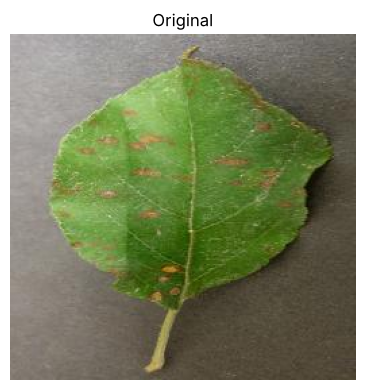

In [3]:
IMAGE_PATH = None   # e.g. "data/raw/plantvillage_apple/train/Apple___Cedar_apple_rust/xyz.jpg"

if IMAGE_PATH is None:
    found = sorted(p for p in (ROOT / "data/raw/plantvillage_apple").glob("train/Apple___Cedar_apple_rust/*")
                   if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    IMAGE_PATH = found[0] if found else None

if IMAGE_PATH:
    bgr = cv2.imread(str(IMAGE_PATH))
    print("Using", Path(IMAGE_PATH).relative_to(ROOT))
else:
    bgr = synthetic_leaf()
    print("No dataset found; using a synthetic leaf. Run scripts/download_plantvillage.py for real images.")

show([rgb(bgr)], ["Original"])

## Step 2: Convert RGB to HSV
Hue is the color itself, saturation is how pure it is, value is how bright it is.

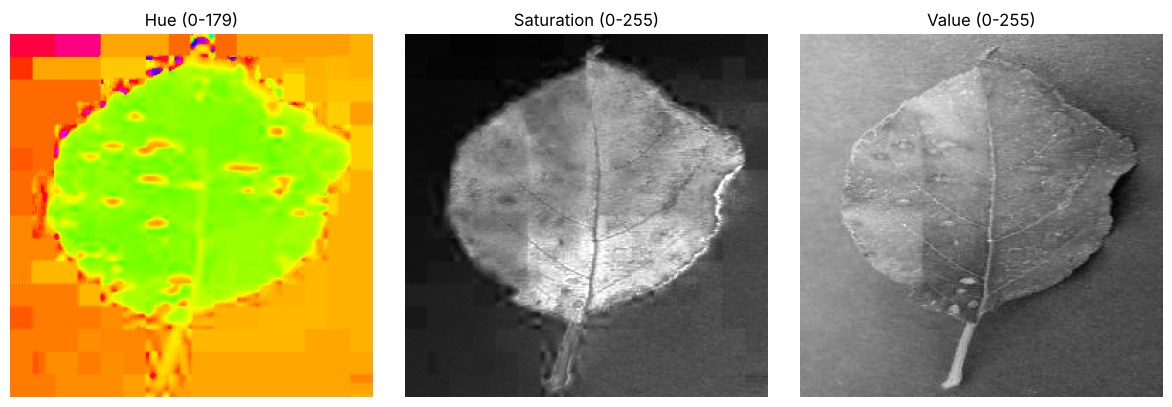

In [4]:
hsv = to_hsv(bgr)
h, s, v = cv2.split(hsv)
show([h, s, v], ["Hue (0-179)", "Saturation (0-255)", "Value (0-255)"], ["hsv", "gray", "gray"])

## Step 3: Thresholds and the binary mask
A pixel turns white only when **all three** of its measurements fall inside a range. Each disease has its own ranges (starting guesses in `src/hsv/thresholds.py`).

cedar_apple_rust  lower=(10, 30, 100)  upper=(32, 255, 255)
apple_scab        lower=(20, 40, 15)  upper=(48, 255, 80)
black_rot         lower=(5, 40, 30)  upper=(22, 255, 220)
black_rot         lower=(150, 50, 30)  upper=(179, 255, 200)
black_rot         lower=(0, 50, 30)  upper=(4, 255, 200)


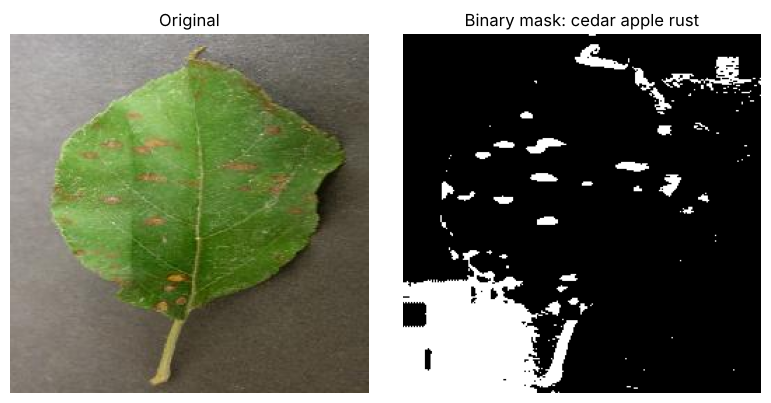

In [5]:
for disease, ranges in DISEASE_RANGES.items():
    for r in ranges:
        print(f"{disease:<17} lower={r.lower}  upper={r.upper}")

rust_mask = threshold_mask(hsv, DISEASE_RANGES["cedar_apple_rust"])
show([rgb(bgr), rust_mask], ["Original", "Binary mask: cedar apple rust"], [None, "gray"])

### Clean the mask and stay on the leaf
Opening removes tiny specks; closing fills small holes. The leaf mask keeps background pixels from ever counting as lesions.

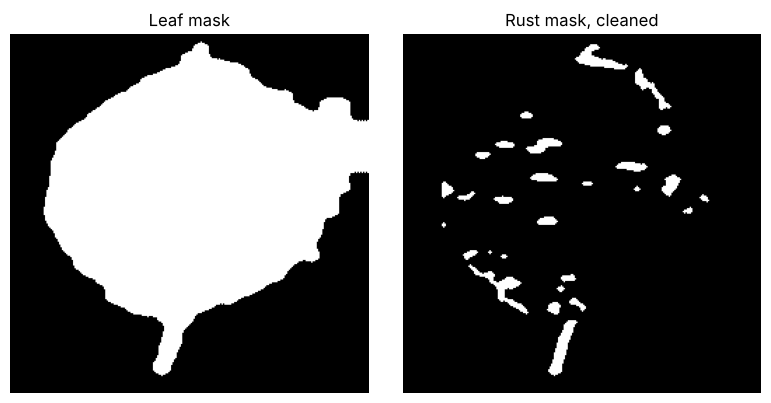

In [6]:
leaf = leaf_region(hsv)
rust_clean = clean_mask(cv2.bitwise_and(rust_mask, leaf))
show([leaf, rust_clean], ["Leaf mask", "Rust mask, cleaned"], ["gray", "gray"])

## Step 4: Apply the mask to the original picture
Only the suspected lesion pixels remain. This is what goes to the CNN.

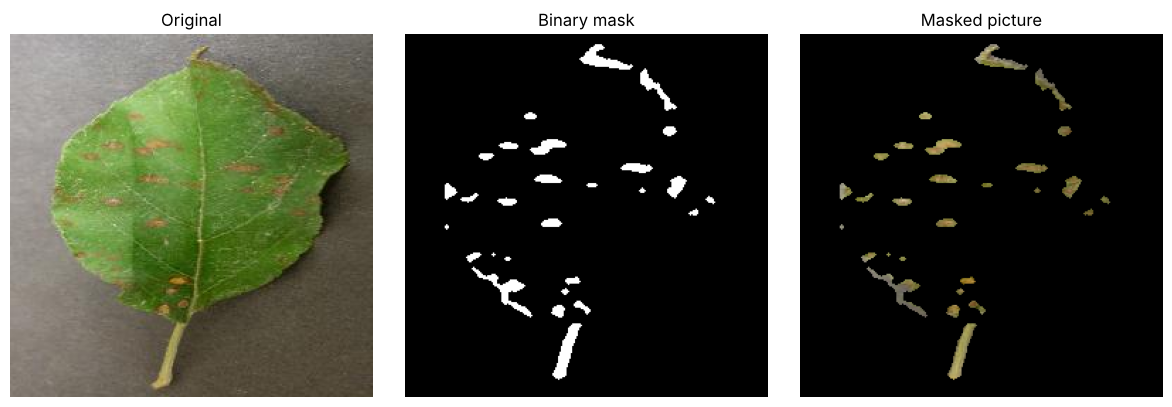

In [7]:
masked = apply_mask(bgr, rust_clean)
show([rgb(bgr), rust_clean, rgb(masked)], ["Original", "Binary mask", "Masked picture"], [None, "gray", None])

## Step 5: Candidate boxes
Each separate white region becomes a box. The CNN will check each box: is it a lesion, and which disease?

20 candidate regions


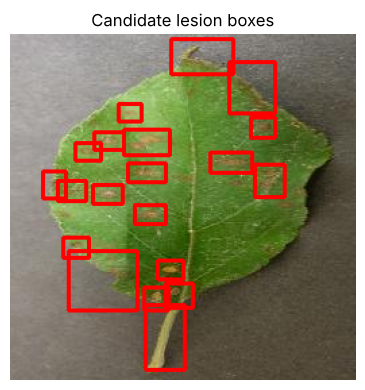

In [8]:
boxes = candidate_boxes(rust_clean, min_area=30)
print(f"{len(boxes)} candidate regions")
show([rgb(draw_boxes(bgr, boxes))], ["Candidate lesion boxes"])

## All diseases at once
`segment_leaf` runs every step for every disease's thresholds. Expect extra regions here: the scab range also catches darker healthy tissue, because scab lesions are olive-green and mainly differ by being darker. That overlap is what the CNN has to sort out.

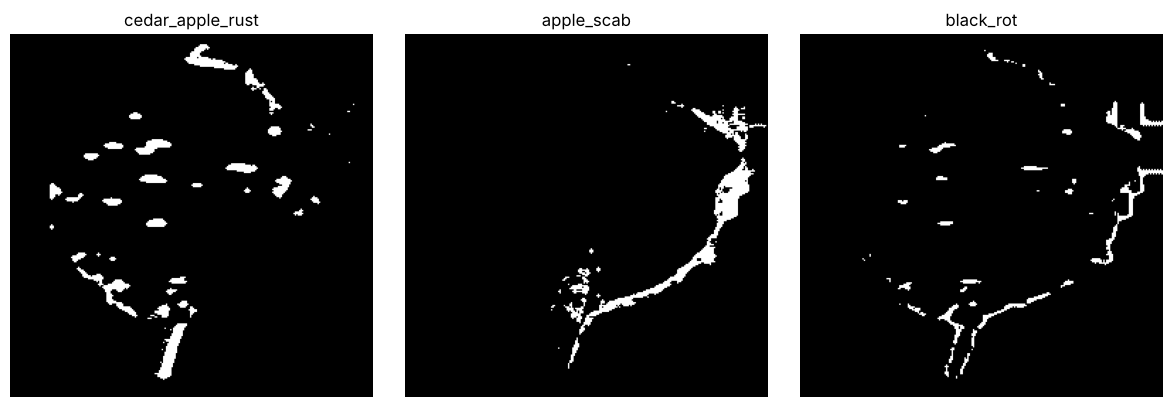

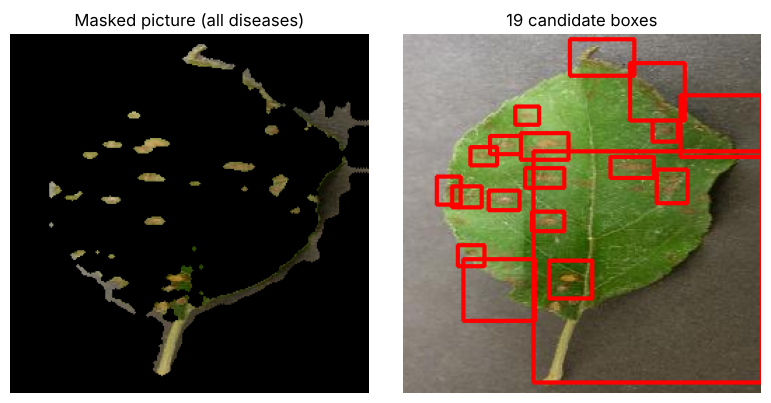

In [9]:
result = segment_leaf(bgr)
masks = [result.per_disease[d] for d in DISEASE_RANGES]
show(masks, list(DISEASE_RANGES), ["gray"] * len(masks))
show([rgb(result.masked), rgb(draw_boxes(bgr, result.boxes))],
     ["Masked picture (all diseases)", f"{len(result.boxes)} candidate boxes"])

## Tuning thresholds by hand
Read the HSV value at a pixel you know is a lesion, then adjust a range and rerun. `x` is the column, `y` the row.

HSV at (128, 128) = [45, 161, 141]


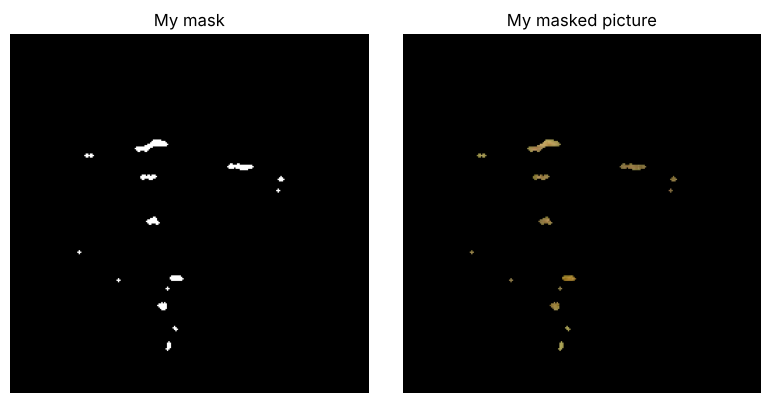

In [10]:
x, y = bgr.shape[1] // 2, bgr.shape[0] // 2
print("HSV at", (x, y), "=", hsv[y, x].tolist())

my_range = HSVRange(lower=(8, 120, 120), upper=(28, 255, 255))   # edit me
my_mask = clean_mask(cv2.bitwise_and(threshold_mask(hsv, [my_range]), leaf))
show([my_mask, rgb(apply_mask(bgr, my_mask))], ["My mask", "My masked picture"], ["gray", None])